In [16]:
import numpy as np 
from pathlib import Path 
from load_file import load_file
from msg import msg 

file_path = Path(r"C:\Users\arni-experiment\Documents\K.Boykin\SDR_PROJECT\rtl-sdr-64bit-20260906\adsb_raw32.bin")

samples = (load_file(file_path))

# Original sample rate 
fs = 3_200_000  # sampling freq 

print("Original IQ samples:", len(samples))
print("Original sample rate:", fs, "samples/sec") 
print("Recording duration:", len(samples) / fs, "seconds")

Original IQ samples: 16000000
Original sample rate: 3200000 samples/sec
Recording duration: 5.0 seconds


Original sample rate: 3200000 samples/sec
Resampled samples: 20000000
New sample rate: 4000000 samples/sec
Resampled duration: 5.0 seconds


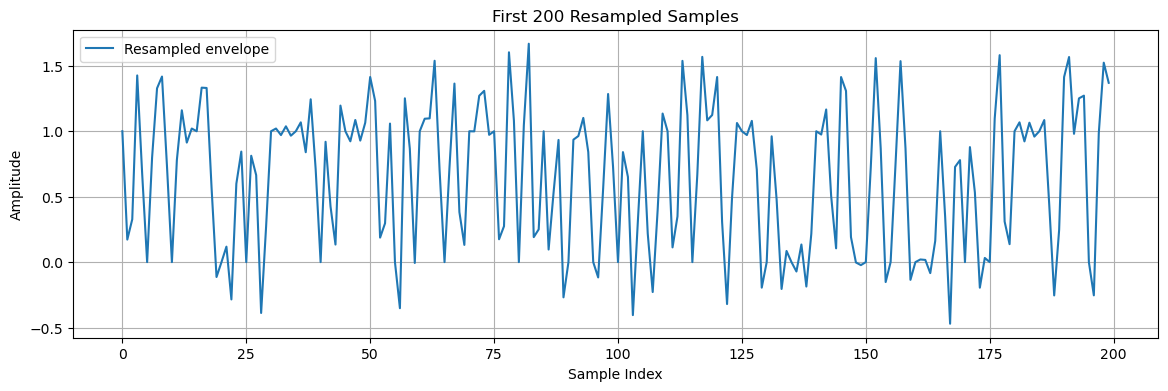

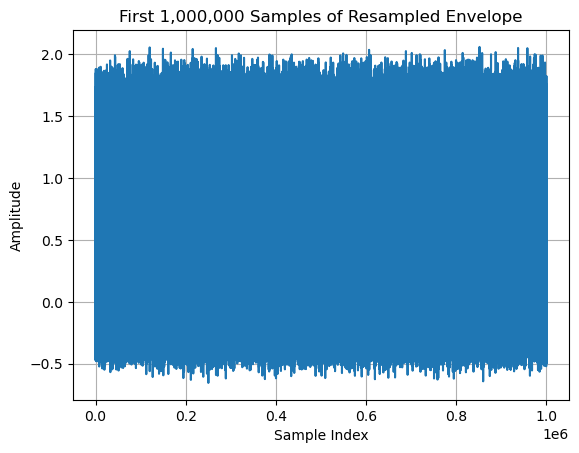

In [17]:
import numpy as np 
from scipy import signal 
import matplotlib.pyplot as plt 

#Upsample to 4 MHz to make the bit boundaries lineup with samples 

fs_original = 3_200_000
fs_new = 4_000_000

data = np.abs(samples)

data = signal.resample_poly(data, 5, 4)

print("Original sample rate:", fs_original, "samples/sec")
print("Resampled samples:", len(data))
print("New sample rate:", fs_new, "samples/sec")
print("Resampled duration:", len(data) / fs_new, "seconds")

plt.figure(figsize=(14, 4))
plt.plot(data[:200], label="Resampled envelope")
plt.title("First 200 Resampled Samples")
plt.xlabel("Sample Index")
plt.ylabel("Amplitude")
plt.grid(True)
plt.legend()
plt.show()

plt.plot(data[:int(1e6)])  
plt.title('First 1,000,000 Samples of Resampled Envelope')  
plt.xlabel('Sample Index')  
plt.ylabel('Amplitude')  
plt.grid(True)  
plt.show() 

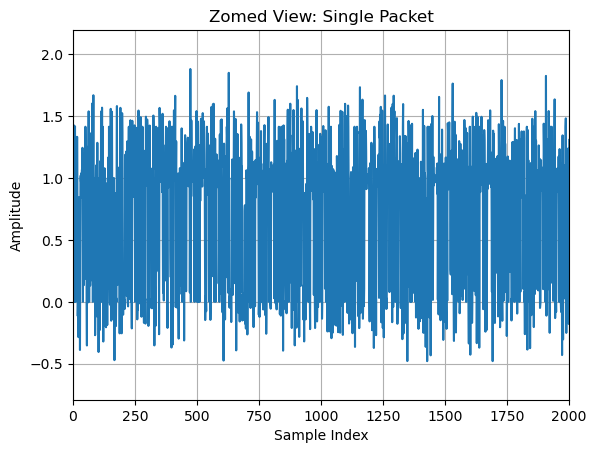

In [18]:
plt.plot(data[:int(1e6)])  

plt.xlim(0, 2000) # approx. range of packet – check by image of plot if shifting needed  
plt.title('Zomed View: Single Packet')  

plt.xlabel('Sample Index')  
plt.ylabel('Amplitude')  

plt.grid(True)  
plt.show()

Input samples: 20000000
Output samples: 10000000
New sample rate: 2000000 samples/sec
Recording duration: 5.0 seconds


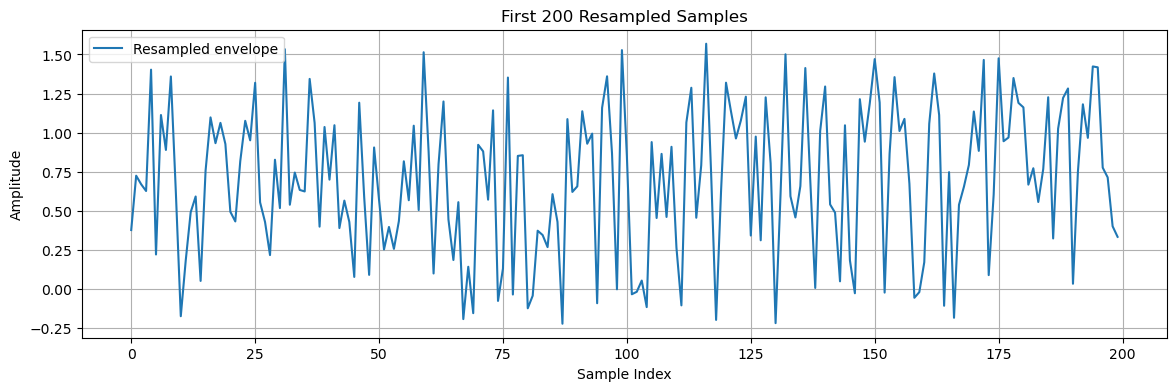

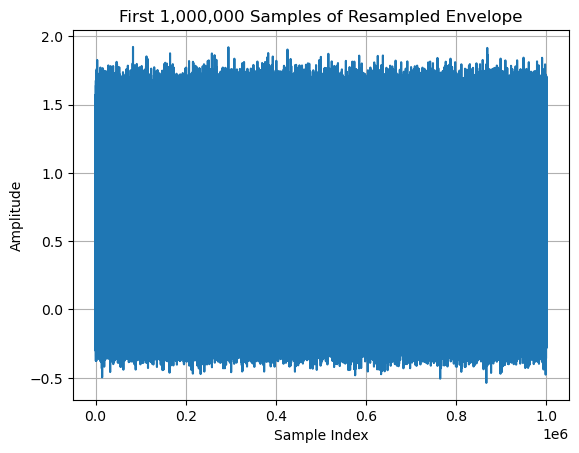

In [19]:
# Sample to 2 MHz to make the bit boundaries lineup with samples 

data2 = signal.resample_poly(data, 1, 2)

fs2 = 2_000_000

print("Input samples:", len(data))
print("Output samples:", len(data2))
print("New sample rate:", fs2, "samples/sec")
print("Recording duration:", len(data2) / fs2, "seconds")

plt.figure(figsize=(14, 4))
plt.plot(data2[:200], label="Resampled envelope")
plt.title("First 200 Resampled Samples")
plt.xlabel("Sample Index")
plt.ylabel("Amplitude")
plt.grid(True)
plt.legend()
plt.show()

plt.plot(data2[:int(1e6)])  
plt.title('First 1,000,000 Samples of Resampled Envelope')  
plt.xlabel('Sample Index')  
plt.ylabel('Amplitude')  
plt.grid(True)  
plt.show() 

Threshold: 1.587844878461267
Number of samples: 20000000
Number of high samples: 301317


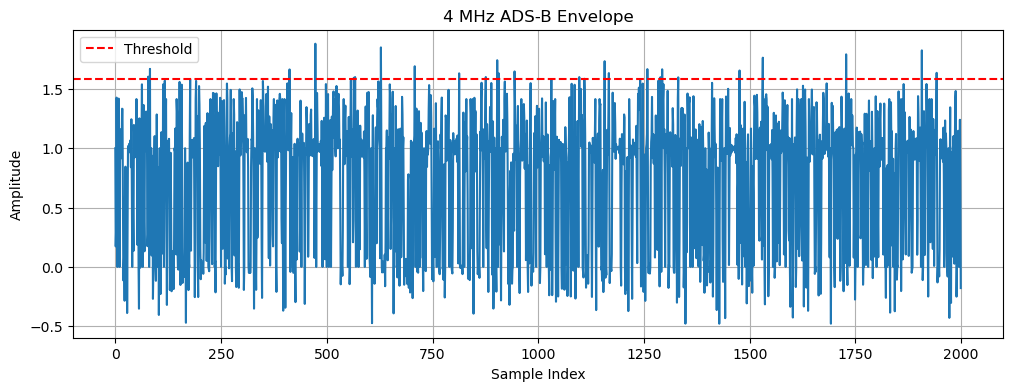

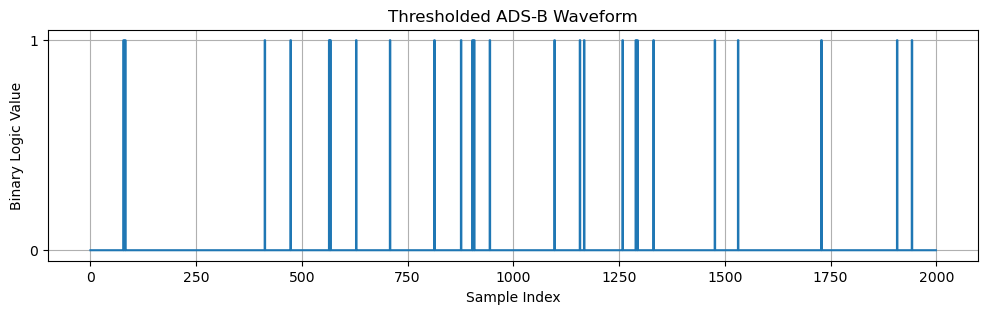

In [20]:
import numpy as np
import matplotlib.pyplot as plt

# Use the complete 4 MHz sampled envelope
packet = data

# Calculate the threshold
peak_amp = np.max(packet)
noise_floor = np.mean(packet)
threshold = (peak_amp + noise_floor) / 2

# Threshold the complete recording
adsb_waveform = (packet > threshold).astype(int)

print("Threshold:", threshold)
print("Number of samples:", len(adsb_waveform))
print("Number of high samples:", np.sum(adsb_waveform))

n = 2000

plt.figure(figsize=(12, 4))
plt.plot(data[:n])
plt.axhline(threshold, linestyle="--", color="red",
            label="Threshold")
plt.title("4 MHz ADS-B Envelope")
plt.xlabel("Sample Index")
plt.ylabel("Amplitude")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(12, 3))
plt.step(np.arange(n), adsb_waveform[:n], where="post")
plt.title("Thresholded ADS-B Waveform")
plt.xlabel("Sample Index")
plt.ylabel("Binary Logic Value")
plt.yticks([0, 1])
plt.grid(True)
plt.show()

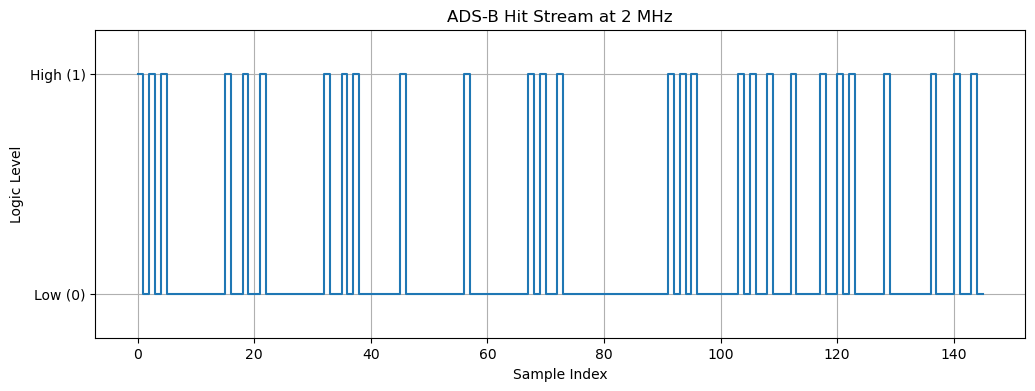

In [23]:
# 1. Subsample by a factor of 2: 4 MHz -> 2 MHz
adsb_hits = adsb_waveform[::2]

# 2. Shift to the first non-zero sample
first_hit = np.flatnonzero(adsb_hits)

if len(first_hit) > 0:
    adsb_hits = adsb_hits[first_hit[0]:]
else:
    print("No non-zero samples found. Check the threshold.")

# 3. Plot the ADS-B hit stream
plt.figure(figsize=(12, 4))
plt.step(np.arange(len(adsb_hits)), adsb_hits, where="post")

plt.title("ADS-B Hit Stream at 2 MHz")
plt.xlabel("Sample Index")
plt.ylabel("Logic Level")
plt.yticks([0, 1], ["Low (0)", "High (1)"])
plt.ylim(-0.2, 1.2)
plt.grid(True)
plt.show()

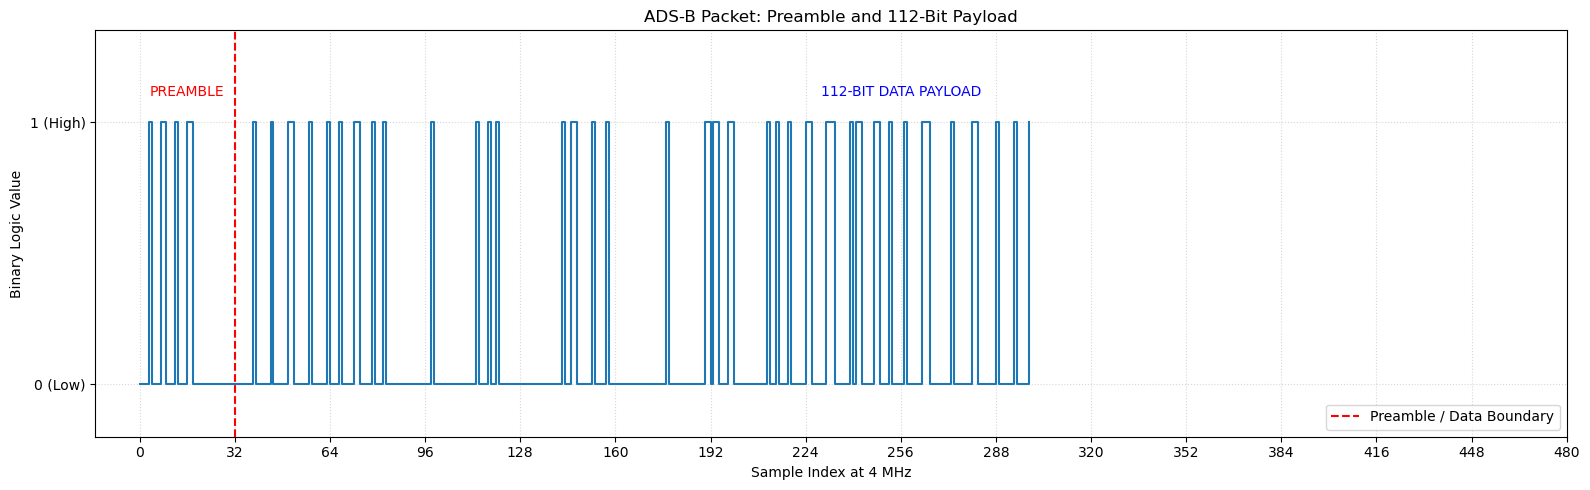

In [29]:

import numpy as np
import matplotlib.pyplot as plt

# Thresholded packet at 4 MHz, starting at the preamble
packet = adsb_waveform[:480]

# Decode the 112 data bits
payload = packet[32:480]
half_bits = payload[::2]
adsb_bits = (half_bits[0::2] > half_bits[1::2]).astype(int)

# Plot the complete packet
plt.figure(figsize=(16, 5))
plt.step(np.arange(len(packet)), packet, where="post")

# Mark the boundary between preamble and data
plt.axvline(32, color="red", linestyle="--", label="Preamble / Data Boundary")

# Label the two regions
plt.text(16, 1.1, "PREAMBLE", ha="center", color="red")
plt.text(256, 1.1, "112-BIT DATA PAYLOAD", ha="center", color="blue")

plt.title("ADS-B Packet: Preamble and 112-Bit Payload")
plt.xlabel("Sample Index at 4 MHz")
plt.ylabel("Binary Logic Value")
plt.xticks(np.arange(0, 481, 32))
plt.yticks([0, 1], ["0 (Low)", "1 (High)"])
plt.ylim(-0.2, 1.35)
plt.grid(True, linestyle=":", alpha=0.5)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


ADS-B Bitstream (112 bits):
0001000000100000000000100000001000000000000000001010001100100010100


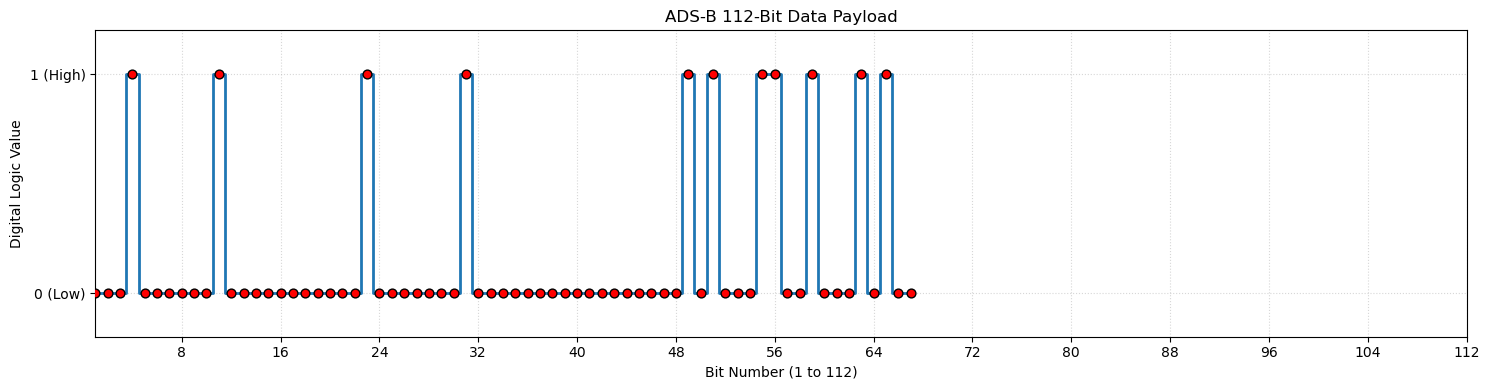

In [26]:
# 1. Thresholded packet at 4 MHz
thresholded_samples = adsb_waveform

# Assumes the packet starts at the preamble
data_start_index = 32

# 2. Extract the 448 samples for the 112-bit payload
raw_data_samples = thresholded_samples[
    data_start_index:data_start_index + 448
]

# 3. Subsample to 2 MHz: one sample per half-bit
half_bits = raw_data_samples[::2]

# 4. Decode each bit by comparing its two half-bits
adsb_bitstream = (
    half_bits[0::2] > half_bits[1::2]
).astype(int)

# 5. Print the 112-bit stream
print("ADS-B Bitstream (112 bits):")
print("".join(map(str, adsb_bitstream)))


# Plot the decoded 112-bit payload
bit_indices = np.arange(1, len(adsb_bitstream) + 1)

plt.figure(figsize=(15, 4))
plt.step(bit_indices, adsb_bitstream, where="mid",
         color="tab:blue", linewidth=2)

plt.scatter(bit_indices, adsb_bitstream,
            color="red", edgecolor="black",
            zorder=3, s=40)

plt.title("ADS-B 112-Bit Data Payload")
plt.xlabel("Bit Number (1 to 112)")
plt.ylabel("Digital Logic Value")
plt.xticks(np.arange(0, 113, 8))
plt.yticks([0, 1], ["0 (Low)", "1 (High)"])
plt.xlim(1, 112)
plt.ylim(-0.2, 1.2)
plt.grid(True, linestyle=":", alpha=0.5)
plt.tight_layout()
plt.show()

In [27]:
import numpy as np
from decode_id import decode_id, hex2bin

# Seven known ADS-B identification packets from the tutorial
pd = [
    "8da6e45a213b5d3340482042cea1",
    "8da6c8262214a075cf68204fa2ea",
    "8da5861e223b4d754538202b41ee",
    "8fa9ee47213b7cf954c820d0b829",
    "8da03f4825184633c75ce0c25fd9",
    "8da2e62120592131df1d609c4876",
    "8da0a457234cb5f5d39e2071ffa5"
]

bta = np.array([
    [0, 0, 0, 0],
    [0, 0, 0, 1],
    [0, 0, 1, 0],
    [0, 0, 1, 1],
    [0, 1, 0, 0],
    [0, 1, 0, 1],
    [0, 1, 1, 0],
    [0, 1, 1, 1],
    [1, 0, 0, 0],
    [1, 0, 0, 1],
    [1, 0, 1, 0],
    [1, 0, 1, 1],
    [1, 1, 0, 0],
    [1, 1, 0, 1],
    [1, 1, 1, 0],
    [1, 1, 1, 1]
])

def hex2bin(s):
    bits = []

    for char in s:
        value = int(char, 16)
        bits.extend(bta[value])

    return np.array(bits, dtype=int)

# Convert each hexadecimal packet into a row of bits
pd = np.array([hex2bin(packet) for packet in pd])

print("Number of packets:", pd.shape[0])
print("Bits per packet:", pd.shape[1])
print("Packet array shape:", pd.shape)
print("First packet bits:")
print("".join(map(str, pd[0])))

Number of packets: 7
Bits per packet: 112
Packet array shape: (7, 112)
First packet bits:
1000110110100110111001000101101000100001001110110101110100110011010000000100100000100000010000101100111010100001


In [28]:
from decode_id import decode_id 

decode_id(pd)

N543PD_
EJA536_
N455QS_
N739UL_
FDX3153
VRD1715
SKW5498
